# CIFAR-10 FCN

## 1. Business Understanding

The goal is to apply and evaluate neural network techniques using CIFAR-10 dataset and FCN (Fully Convolutional Network) model.

## 2. Data Understanding

In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

In [2]:
import keras
from keras import layers
print(keras.__version__, keras.backend.backend())
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.utils import to_categorical
import pandas as pd
import time

3.15.1 tensorflow


In [3]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

In [4]:
print(f'x_train shape: {x_train.shape}')
print(f'x_test shape:  {x_test.shape}')
print(f'y_train shape: {y_train.shape}')
print(f'y_test shape:  {y_test.shape}')

x_train shape: (50000, 32, 32, 3)
x_test shape:  (10000, 32, 32, 3)
y_train shape: (50000, 1)
y_test shape:  (10000, 1)


The data consists of 60,000 32x32 colour images split into 50,000 training and 10,000 test images. Images have been split into 10 classes airplane, automobile, bird, cat, deer, dog, frog, horse, ship and truck with no overlap between classes.  
[source](https://cave.cs.toronto.edu/kriz/cifar.html)

## 3. Data Preprocessing

In [5]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

mean = x_train.mean(axis=(0, 1, 2))
std = x_train.std(axis=(0, 1, 2))
print("mean:", mean)
print("std: ", std)

x_train = (x_train - mean) / std
x_test = (x_test - mean) / std

X_train = x_train.reshape(50000, 3072)
X_test = x_test.reshape(10000, 3072)

y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

mean: [0.4914009  0.48215896 0.4465308 ]
std:  [0.24703279 0.24348423 0.26158753]


## 4. Modeling

### Neuronien ja kerrosten määrien vertailu

Vertaillaan mallin suorityskykyä neuronien ja kerrosten määrän perusteella.
Kokeilussa on `512`, `256` ja `128` neuronin ensimmäinen kerros, toiseen kerroksen kokeiluilla neuronien määrä puolitetaan.

In [9]:
results = []
histories = {}
def build_model(units, n_layers):
    layers = [keras.Input(shape=(3072,))]
    width = units
    for _ in range(n_layers):
        layers.append(keras.layers.Dense(width, activation="relu"))
        width = max(width // 2, 16)
    layers.append(keras.layers.Dense(10, activation="softmax"))
    model = keras.Sequential(layers)
    model.compile(optimizer="adam",
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])
    return model

for units in [128, 256, 512]:
    for n_layers in [1, 2]:
        callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,restore_best_weights=True)]
        keras.utils.set_random_seed(42)
        model = build_model(units, n_layers)

        t0 = time.perf_counter()
        history = model.fit(X_train, y_train, epochs=20, batch_size=64,
                            validation_split=0.2, verbose=0, callbacks=callbacks)
        train_time = time.perf_counter() - t0

        test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
        key = f"{units} neuronia, {n_layers} kerrosta"
        histories[key] = history.history
        best_epoch = int(np.argmin(history.history["val_loss"]))

        results.append({
            "neuronit": units,
            "kerrokset": n_layers,
            "parametreja": model.count_params(),
            "aika_s": train_time / len(history.history["loss"]),
            "paras_epookki": best_epoch + 1,
            "epookkeja_ajettu": len(history.history["loss"]),
            "train_acc": history.history["accuracy"][best_epoch],
            "val_acc": history.history["val_accuracy"][best_epoch],
            "ero_train_val": history.history["accuracy"][best_epoch]
                     - history.history["val_accuracy"][best_epoch],
            "test_acc": test_acc,
        })
        print(key, "->", round(test_acc, 4), f"({train_time/len(history.history['loss']):.1f} s)")
df = pd.DataFrame(results)

128 neuronia, 1 kerrosta -> 0.4764 (1.0 s)
128 neuronia, 2 kerrosta -> 0.4796 (1.1 s)
256 neuronia, 1 kerrosta -> 0.4638 (1.3 s)
256 neuronia, 2 kerrosta -> 0.4772 (1.4 s)
512 neuronia, 1 kerrosta -> 0.4654 (2.0 s)
512 neuronia, 2 kerrosta -> 0.4684 (2.2 s)


In [10]:
df

,neuronit,kerrokset,parametreja,aika_s,paras_epookki,epookkeja_ajettu,train_acc,val_acc,ero_train_val,test_acc
0,128,1,394634,1.022406,4,7,0.536700,0.4689,0.067800,0.4764
1,128,2,402250,1.068373,4,7,0.517575,0.4614,0.056175,0.4796
2,256,1,789258,1.341049,3,6,0.522900,0.4706,0.052300,0.4638
3,256,2,820874,1.446499,4,7,0.530150,0.4745,0.055650,0.4772
4,512,1,1578506,2.037043,2,5,0.484575,0.4596,0.024975,0.4654
5,512,2,1707274,2.227534,3,6,0.503475,0.4578,0.045675,0.4684


Testeistä selviää että mallin koko ei juurikaan paranna mallin suorituskykyä, mutta suuremmalla mallilla jossa `512` neuronia ja `2` kerrosta aika on yli kaksinkertainen per epoch. `val_acc` on paras `256` neuronilla jossa 2 kerrosta, toisessa kerroksessa `128` neuronia.

In [11]:
model = keras.Sequential([
    keras.Input(shape=(3072,)),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
full_history = model.fit(X_train, y_train, epochs=20, batch_size=64,
                    validation_split=0.2, verbose=2)
print("\n")
model = keras.Sequential([
    keras.Input(shape=(3072,)),
    keras.layers.Dense(512, activation="relu"),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
history = model.fit(X_train, y_train, epochs=20, batch_size=64,
                    validation_split=0.2, verbose=2, callbacks=callbacks)

Epoch 1/20
625/625 - 2s - 2ms/step - accuracy: 0.3720 - loss: 1.8109 - val_accuracy: 0.4078 - val_loss: 1.6935
Epoch 2/20
625/625 - 1s - 2ms/step - accuracy: 0.4522 - loss: 1.5600 - val_accuracy: 0.4387 - val_loss: 1.6018
Epoch 3/20
625/625 - 1s - 2ms/step - accuracy: 0.4888 - loss: 1.4507 - val_accuracy: 0.4513 - val_loss: 1.5762
Epoch 4/20
625/625 - 1s - 2ms/step - accuracy: 0.5153 - loss: 1.3710 - val_accuracy: 0.4622 - val_loss: 1.5605
Epoch 5/20
625/625 - 1s - 2ms/step - accuracy: 0.5359 - loss: 1.3094 - val_accuracy: 0.4709 - val_loss: 1.5463
Epoch 6/20
625/625 - 1s - 2ms/step - accuracy: 0.5573 - loss: 1.2512 - val_accuracy: 0.4726 - val_loss: 1.5526
Epoch 7/20
625/625 - 1s - 2ms/step - accuracy: 0.5735 - loss: 1.2006 - val_accuracy: 0.4746 - val_loss: 1.5739
Epoch 8/20
625/625 - 1s - 2ms/step - accuracy: 0.5901 - loss: 1.1535 - val_accuracy: 0.4709 - val_loss: 1.6108
Epoch 9/20
625/625 - 1s - 2ms/step - accuracy: 0.6062 - loss: 1.1080 - val_accuracy: 0.4735 - val_loss: 1.6240
E

## 5. Evaluation

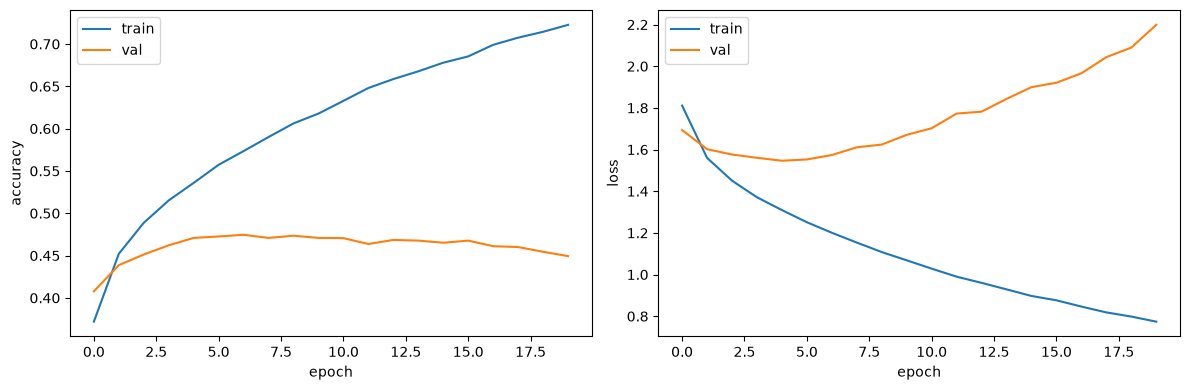

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(full_history.history["accuracy"], label="train")
axes[0].plot(full_history.history["val_accuracy"], label="val")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("accuracy")
axes[0].legend()

axes[1].plot(full_history.history["loss"], label="train")
axes[1].plot(full_history.history["val_loss"], label="val")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("loss")
axes[1].legend()

plt.tight_layout()
plt.show()

yllä olevista kuvaajista voimme päätellä `val_loss` noususta että malli ylioppii (overfit). Lisätään aikaisemppiin mallinkoulutuksiin callback joka pysäyttää ja palauttaa parametrit jolloin `val_loss` alkoi nousta.

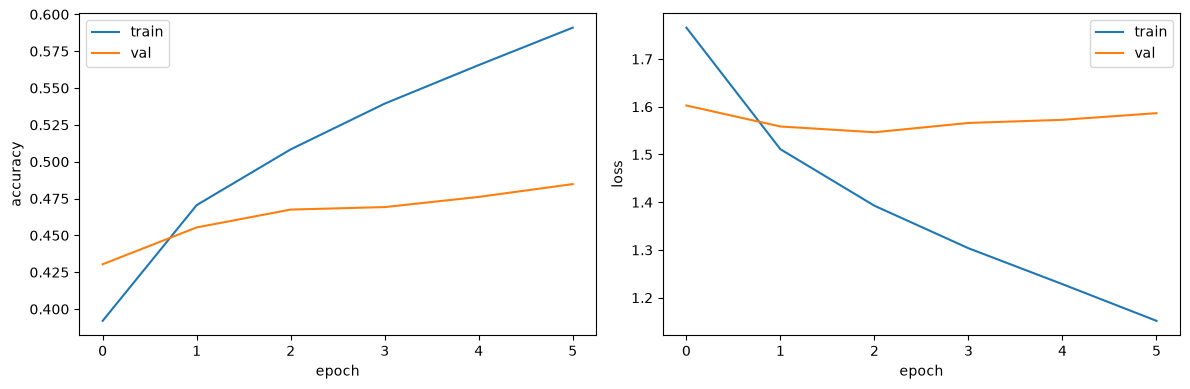

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="train")
axes[0].plot(history.history["val_accuracy"], label="val")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="train")
axes[1].plot(history.history["val_loss"], label="val")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("loss")
axes[1].legend()

plt.tight_layout()
plt.show()

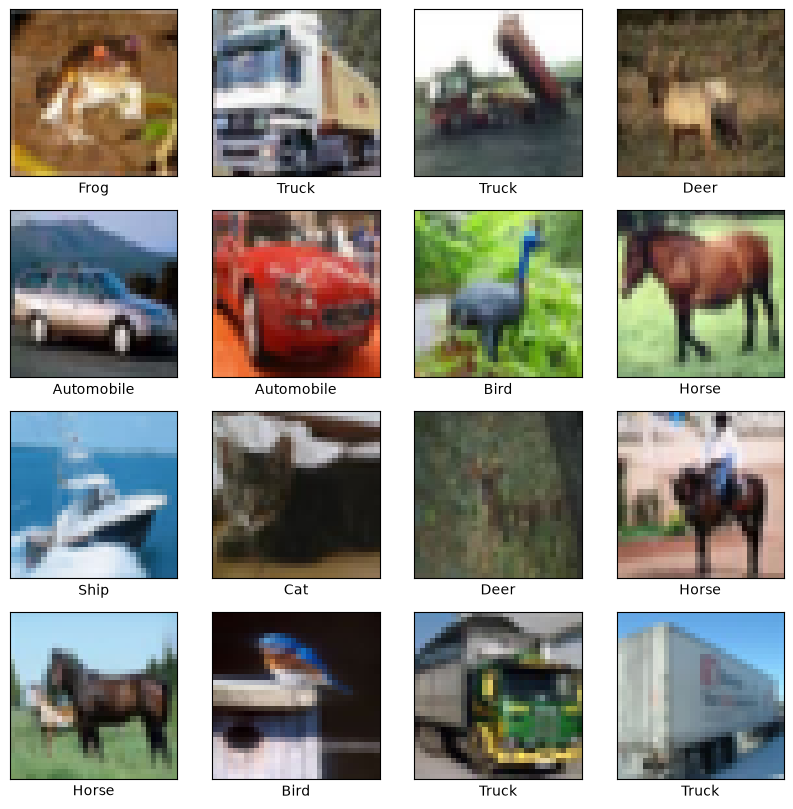

In [14]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

class_names = ['Airplane','Automobile','Bird','Cat','Deer','Dog','Frog','Horse','Ship','Truck']

plt.figure(figsize=(10,10))
for i in range(16):
    plt.subplot(4,4,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i])
    plt.xlabel(class_names[y_train[i][0]])
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 678us/step
(10000, 10) 1.0


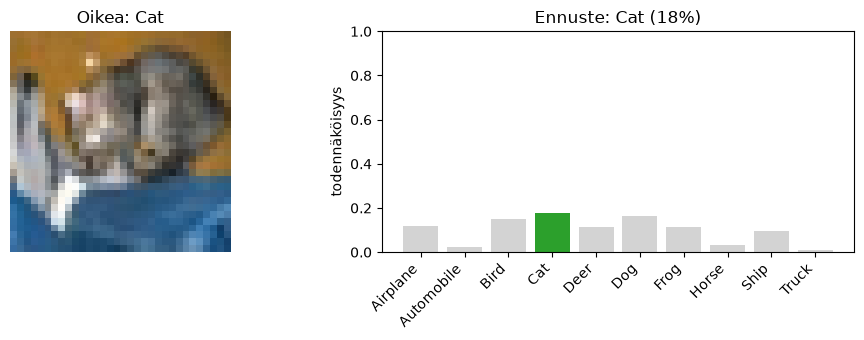

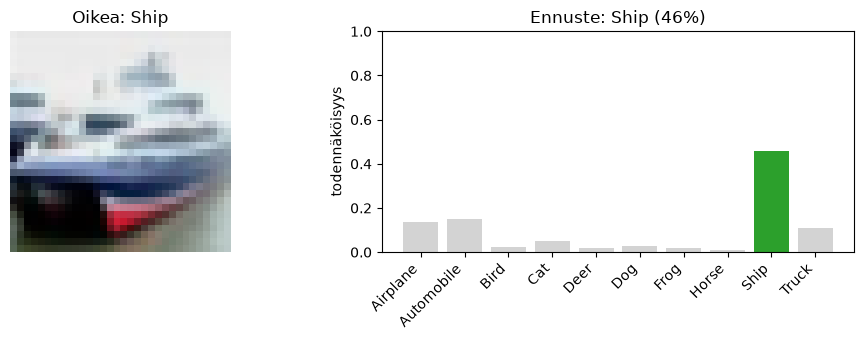

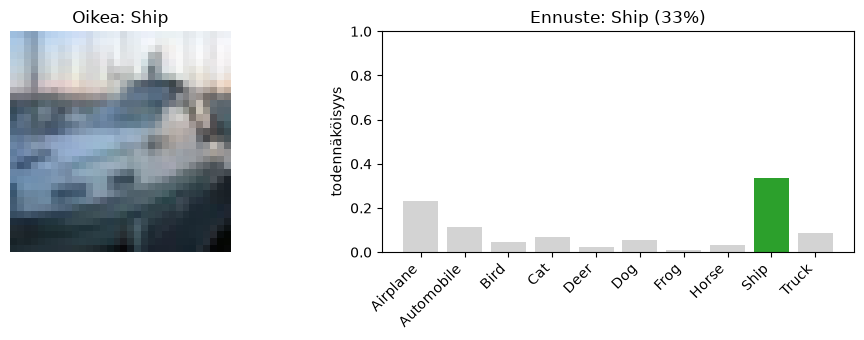

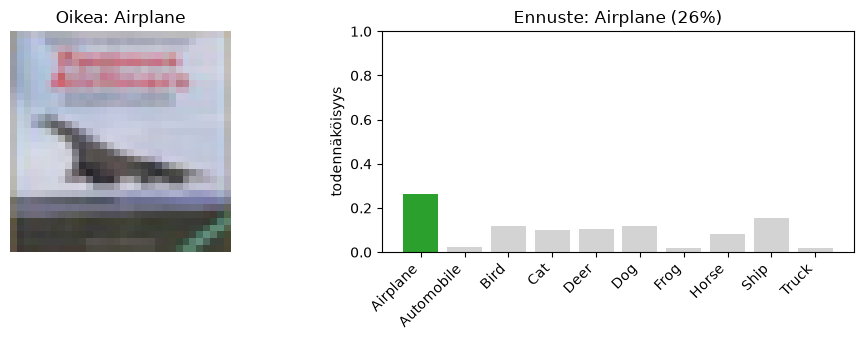

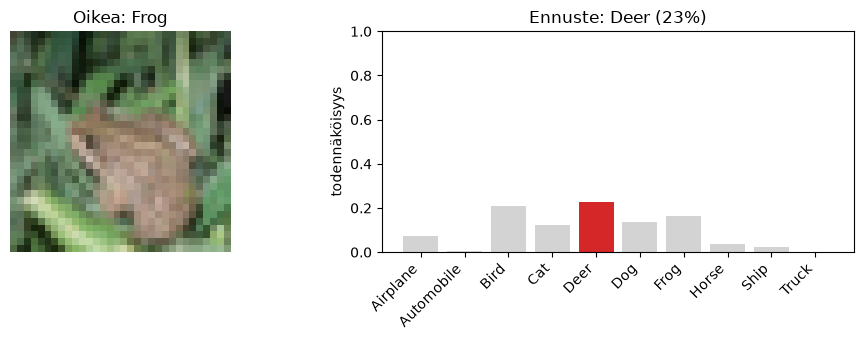

In [24]:
x_test_flat = x_test.reshape(10000, 3072)
probs = model.predict(x_test_flat)
print(probs.shape, probs[0].sum())

(_, _), (x_test_img, y_test_int) = keras.datasets.cifar10.load_data()
x_test_img = x_test_img.astype("float32") / 255
y_test_int = y_test_int.flatten()

def plot_prediction(i, probs, images_img, true_labels):
    pred = np.argmax(probs[i])
    true = true_labels[i]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))

    ax1.imshow(images_img[i])
    ax1.axis("off")
    ax1.set_title(f"Oikea: {class_names[true]}")

    colors = ["lightgray"] * 10
    colors[pred] = "tab:red" if pred != true else "tab:green"
    ax2.bar(range(10), probs[i], color=colors)
    ax2.set_xticks(range(10))
    ax2.set_xticklabels(class_names, rotation=45, ha="right")
    ax2.set_ylim(0, 1)
    ax2.set_ylabel("todennäköisyys")
    ax2.set_title(f"Ennuste: {class_names[pred]} ({probs[i][pred]:.0%})")

    plt.tight_layout()
    plt.show()

for i in range(5):
    plot_prediction(i, probs, x_test_img, y_test_int)